<table>
    <tr>
        <td colspan=2><strong>International University of La Rioja (UNIR)</strong></td>
    </tr>
    <tr>
        <td colspan=2><strong>Master's Degree in Mathematical Engineering and Computing</strong></td>
    </tr>
    <tr>
        <td>Master's thesis submitted by:</td>
        <td><strong>Andrés Benavides, Diego Salamanca, Yeferson Salamanca.</strong></td>
    </tr>
    <tr>
        <td>Supervisor:</td>
        <td>PhD. Juan Francisco Martínez Cerda</td>
    </tr>
</table>


---


# 05 - LSTM trend classifier (Keras)

This notebook trains a stacked **LSTM** classifier on the sliding-window sequences produced by `04_preprocess_data.ipynb` to predict the next day's **SELL / HOLD / BUY** trend label.

**Inputs**
- `data/datasets/{train,val,test}/X.npy` and `.../y.npy` - scaled sequences `(n_samples, window_size, n_features)` and integer labels.
- `data/datasets/feature_metadata.json` - feature names, window size, class mapping (written by notebook 03).
- `metadata/model_config.json` - **all tunable hyperparameters** (learning rate, epochs, batch size, layer sizes, callbacks...). Edit this file and rerun to experiment.

**Outputs** (in `data/models/`)
- `lstm_trend_classifier.keras` - the trained model (configurable filename).
- `training_history.json` - training and validation loss/accuracy per epoch.
- `model_report.json` - resolved configuration + best-epoch metrics + test metrics + per-class and per-ticker accuracy.
- `test_latest_recommendations.csv` - the latest test-window BUY/HOLD/SELL recommendation per ticker.

**Sections**
1. Imports, paths, reproducible seed.
2. Load `model_config.json` (with built-in defaults as fallback).
3. Load datasets + feature metadata.
4. Build and compile the LSTM model.
5. Train (with EarlyStopping / ReduceLROnPlateau).
6. Plot training and validation loss / accuracy history.
7. Evaluate loss and accuracy on the test set.
8. Save the model, training history, and report.

**Configuration keys (`metadata/model_config.json`)**
- `learning_rate`, `epochs`, `batch_size` - main training controls.
- `lstm_units` - list of units per stacked LSTM layer (e.g. `[64, 32]`).
- `dropout` / `recurrent_dropout` - regularization applied after / within each LSTM layer.
- `dense_units` - optional list of additional Dense layers before the softmax output.
- `optimizer`, `loss` - currently `adam` and `sparse_categorical_crossentropy` (integer labels).
- `early_stopping`, `reduce_lr` - callback settings (`enabled`, `monitor`, `patience`, ...).
- `use_class_weights` - if true, weight classes inversely to their frequency in training.
- `shuffle` - shuffle training samples between epochs.
- `random_seed`, `dataset_dir`, `model_dir`, `model_filename` - reproducibility and relative paths.

## 1. Imports, paths, and seed

In [23]:
import json
import logging
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import models, layers

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
    datefmt="%H:%M:%S",
)
logger = logging.getLogger("lstm_model")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CONFIG_PATH = PROJECT_ROOT / "metadata" / "model_config.json"

print(f"PROJECT_ROOT  : {PROJECT_ROOT}")
print(f"CONFIG_PATH   : {CONFIG_PATH}")
print(f"TensorFlow    : {tf.__version__}")
print(f"Keras         : {keras.__version__}")

PROJECT_ROOT  : /Applications/TFM_LSTM
CONFIG_PATH   : /Applications/TFM_LSTM/metadata/model_config.json
TensorFlow    : 2.20.0
Keras         : 3.10.0


## 2. Load configuration

Load all tunable hyperparameters from `metadata/model_config.json`. Edit the JSON and rerun from here to experiment.

In [24]:
if CONFIG_PATH.exists():
    with CONFIG_PATH.open("r", encoding="utf-8") as f:
        cfg = json.load(f)
    logger.info("Loaded config from %s", CONFIG_PATH)
else:
    cfg = {}
    logger.warning("No config at %s - using built-in defaults", CONFIG_PATH)

SEED = int(cfg["random_seed"])
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

DATASET_DIR = PROJECT_ROOT / cfg["dataset_dir"]
MODEL_DIR = PROJECT_ROOT / cfg["model_dir"]

print("Resolved configuration:")
print(json.dumps(cfg, indent=2))
print(f"\nDATASET_DIR : {DATASET_DIR}")
print(f"MODEL_DIR   : {MODEL_DIR}")

14:59:01 | INFO | Loaded config from /Applications/TFM_LSTM/metadata/model_config.json


Resolved configuration:
{
  "learning_rate": 0.001,
  "epochs": 24,
  "batch_size": 64,
  "optimizer": "adam",
  "loss": "sparse_categorical_crossentropy",
  "early_stopping": {
    "enabled": true,
    "monitor": "val_loss",
    "patience": 5,
    "restore_best_weights": true
  },
  "reduce_lr": {
    "enabled": true,
    "monitor": "val_loss",
    "factor": 0.33,
    "patience": 5,
    "min_lr": 1e-07
  },
  "use_class_weights": true,
  "shuffle": true,
  "random_seed": 42,
  "dataset_dir": "data/datasets",
  "model_dir": "data/models",
  "model_filename": "lstm_trend_classifier.keras"
}

DATASET_DIR : /Applications/TFM_LSTM/data/datasets
MODEL_DIR   : /Applications/TFM_LSTM/data/models


## 3. Load datasets and feature metadata

Load the `(X, y)` arrays for each split and the `feature_metadata.json` written by notebook 03. From the metadata, we recover `window_size`, `n_features`, and the ordered class names (from `class_mapping`) so the model and plots remain consistent with how the data was constructed.

In [ ]:
def load_split(split: str) -> tuple[np.ndarray, np.ndarray]:
    """Load X/y arrays for a given split from the dataset directory."""
    x = np.load(DATASET_DIR / split / "X.npy")
    y = np.load(DATASET_DIR / split / "y.npy")
    return x, y


META_PATH = DATASET_DIR / "feature_metadata.json"
if not META_PATH.exists():
    raise FileNotFoundError(
        f"Missing {META_PATH}. Run 04_preprocess_data.ipynb first."
    )
with META_PATH.open("r", encoding="utf-8") as f:
    feature_metadata = json.load(f)

X_train, y_train = load_split("train")
X_val, y_val = load_split("val")
X_test, y_test = load_split("test")

WINDOW_SIZE = int(feature_metadata["window_size"])
N_FEATURES = int(feature_metadata["n_features"])
FEATURE_NAMES = feature_metadata["feature_names"]
CLASS_MAP = {k: int(v) for k, v in feature_metadata["class_mapping"].items()}
# Ordered class names by their integer code (index 0..n-1).
CLASS_NAMES = [name for name, _ in sorted(CLASS_MAP.items(), key=lambda kv: kv[1])]
N_CLASSES = len(CLASS_NAMES)

assert X_train.shape[1:] == (WINDOW_SIZE, N_FEATURES), (
    f"Train X shape {X_train.shape} does not match metadata "
    f"(window={WINDOW_SIZE}, features={N_FEATURES})"
)

print(f"Feature names ({N_FEATURES}): {FEATURE_NAMES}")
print(f"Class names           : {CLASS_NAMES}")
print(f"Window size           : {WINDOW_SIZE}")
print()
for name, (X, y) in {"train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)}.items():
    dist = {CLASS_NAMES[c]: int((y == c).sum()) for c in range(N_CLASSES)}
    print(f"  {name:<5s} X={X.shape}  y={y.shape}  classes={dist}")

Feature names (13): ['logret_1d', 'logret_5d', 'logret_10d', 'logret_20d', 'logret_50d', 'log_price_ma10', 'log_price_ma50', 'rsi_14', 'log_vol_ratio', 'realized_vol', 'macro::^VIX::logret5', 'macro::DX-Y.NYB::logret5', 'macro::^TNX::logret5']
Class names           : ['SELL_100%', 'SELL_50%', 'HOLD', 'BUY_500USD', 'BUY_1000USD']
Window size           : 60

  train X=(60125, 60, 13)  y=(60125,)  classes={'SELL_100%': 1298, 'SELL_50%': 5049, 'HOLD': 45686, 'BUY_500USD': 6960, 'BUY_1000USD': 1132}
  val   X=(4800, 60, 13)  y=(4800,)  classes={'SELL_100%': 156, 'SELL_50%': 527, 'HOLD': 3587, 'BUY_500USD': 468, 'BUY_1000USD': 62}
  test  X=(4600, 60, 13)  y=(4600,)  classes={'SELL_100%': 46, 'SELL_50%': 303, 'HOLD': 3523, 'BUY_500USD': 588, 'BUY_1000USD': 140}


## 4. Build and compile the model

A configuration-driven stacked LSTM: one LSTM layer per entry in `lstm_units` (all but the last return sequences), each followed by `Dropout`, optional additional `Dense` layers, and a final `Dense(N_CLASSES, softmax)`. Compiled with Adam at `learning_rate`, `sparse_categorical_crossentropy` (integer labels), and accuracy.

In [26]:
def build_model(cfg: dict, window_size: int, n_features: int, n_classes: int) -> keras.Model:
    """Build a stacked LSTM classifier from the config."""

    model = models.Sequential([
        layers.Input(shape=(window_size, n_features)),
        layers.LSTM(128, return_sequences=True),
        layers.BatchNormalization(),
        layers.Dropout(0.3),

        layers.LSTM(64, return_sequences=False),
        layers.BatchNormalization(),
        layers.Dropout(0.3),

        layers.Dense(32, activation='relu'),
        layers.Dropout(0.2),
        layers.Dense(n_classes, activation='softmax')
    ])

    optimizer_name = str(cfg["optimizer"]).lower()
    if optimizer_name == "adam":
        optimizer = keras.optimizers.Adam(learning_rate=float(cfg["learning_rate"]))
    else:
        optimizer = keras.optimizers.get(
            {"class_name": optimizer_name, "config": {"learning_rate": float(cfg["learning_rate"])}}
        )

    model.compile(optimizer=optimizer, loss=cfg["loss"], metrics=["accuracy"])
    return model


model = build_model(cfg, WINDOW_SIZE, N_FEATURES, N_CLASSES)
model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (None, 60, 128)        │        72,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 60, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 60, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 125,125 (488.77 KB)

 Trainable params: 124,741 (487.27 KB)

 Non-trainable params: 384 (1.50 KB)

## 5. Train the model

Train on the training split using the validation split for monitoring. EarlyStopping and ReduceLROnPlateau are added when enabled in the configuration. If `use_class_weights` is true, class weights inversely proportional to training frequencies are passed to `fit` to counteract mild class imbalance.

In [27]:
callbacks = []
es_cfg = cfg.get("early_stopping")
if es_cfg.get("enabled"):
    callbacks.append(
        keras.callbacks.EarlyStopping(
            monitor=es_cfg.get("monitor"),
            patience=int(es_cfg.get("patience")),
            restore_best_weights=bool(es_cfg.get("restore_best_weights")),
            verbose=1,
        )
    )

rlr_cfg = cfg.get("reduce_lr")
if rlr_cfg.get("enabled"):
    callbacks.append(
        keras.callbacks.ReduceLROnPlateau(
            monitor=rlr_cfg.get("monitor"),
            factor=float(rlr_cfg.get("factor")),
            patience=int(rlr_cfg.get("patience")),
            min_lr=float(rlr_cfg.get("min_lr")),
            verbose=1,
        )
    )

class_weight = None
if cfg.get("use_class_weights"):
    counts = np.bincount(y_train, minlength=N_CLASSES).astype(float)
    total = counts.sum()
    class_weight = {c: float(total / (N_CLASSES * counts[c])) for c in range(N_CLASSES)}
    print(f"Using class weights: {class_weight}")

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=int(cfg["epochs"]), # change this line to epochs=2, if you want to check results quickly, otherwise keep, epochs=int(cfg["epochs"])
    batch_size=int(cfg["batch_size"]),
    shuffle=bool(cfg["shuffle"]),
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=2,
)

print(f"\nTrained for {len(history.history['loss'])} epochs.")

Using class weights: {0: 9.264252696456087, 1: 2.381659734600911, 2: 0.263209736024165, 3: 1.7277298850574712, 4: 10.62279151943463}
Epoch 1/24


2026-06-12 14:59:01.760043: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


940/940 - 64s - 68ms/step - accuracy: 0.2455 - loss: 1.6442 - val_accuracy: 0.3423 - val_loss: 1.4738 - learning_rate: 1.0000e-03
Epoch 2/24
940/940 - 60s - 64ms/step - accuracy: 0.2853 - loss: 1.5088 - val_accuracy: 0.3290 - val_loss: 1.5103 - learning_rate: 1.0000e-03
Epoch 3/24
940/940 - 110s - 117ms/step - accuracy: 0.3076 - loss: 1.4299 - val_accuracy: 0.3756 - val_loss: 1.4911 - learning_rate: 1.0000e-03
Epoch 4/24
940/940 - 85s - 91ms/step - accuracy: 0.3388 - loss: 1.3447 - val_accuracy: 0.4071 - val_loss: 1.3859 - learning_rate: 1.0000e-03
Epoch 5/24
940/940 - 62s - 66ms/step - accuracy: 0.3361 - loss: 1.2546 - val_accuracy: 0.3713 - val_loss: 1.3906 - learning_rate: 1.0000e-03
Epoch 6/24
940/940 - 60s - 63ms/step - accuracy: 0.3556 - loss: 1.1664 - val_accuracy: 0.3354 - val_loss: 1.4595 - learning_rate: 1.0000e-03
Epoch 7/24
940/940 - 60s - 64ms/step - accuracy: 0.3800 - loss: 1.0801 - val_accuracy: 0.3944 - val_loss: 1.3832 - learning_rate: 1.0000e-03
Epoch 8/24
940/940 - 5

## 6. Training and validation history

Loss and accuracy per epoch for both the training and validation splits. A growing gap between training and validation curves indicates overfitting; EarlyStopping restores the best validation weights.

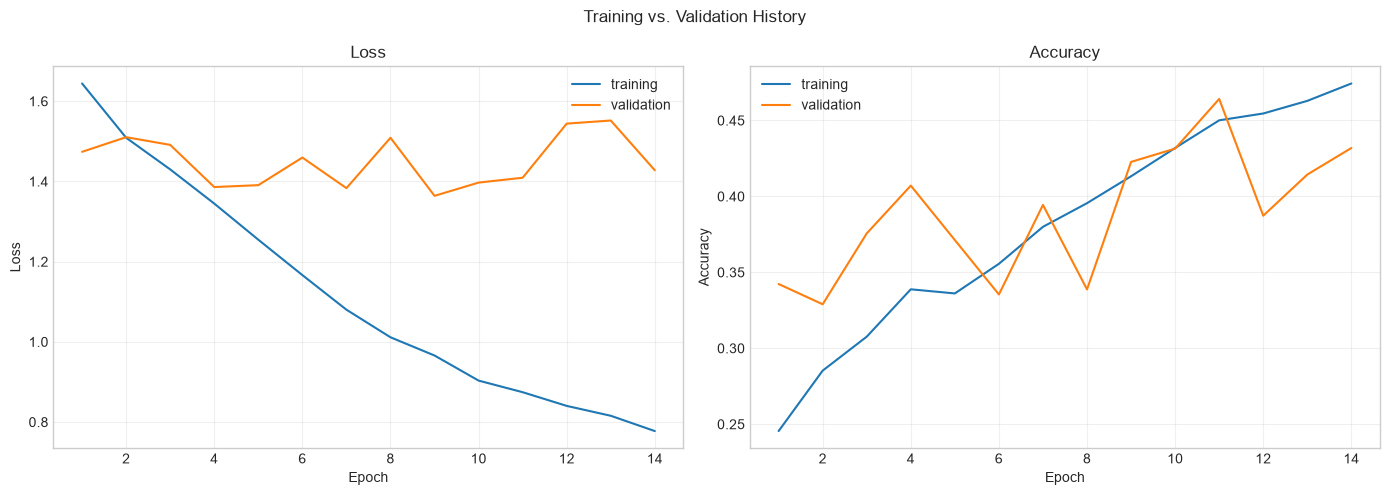

Best epoch (min val_loss) : 9
  train loss / acc        : 0.9659 / 0.4133
  val   loss / acc        : 1.3640 / 0.4227


In [30]:
hist = history.history
epochs_ran = range(1, len(hist["loss"]) + 1)

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(14, 5))

ax_loss.plot(epochs_ran, hist["loss"], label="training")
ax_loss.plot(epochs_ran, hist["val_loss"], label="validation")
ax_loss.set_title("Loss")
ax_loss.set_xlabel("Epoch")
ax_loss.set_ylabel("Loss")
ax_loss.legend()
ax_loss.grid(alpha=0.3)

ax_acc.plot(epochs_ran, hist["accuracy"], label="training")
ax_acc.plot(epochs_ran, hist["val_accuracy"], label="validation")
ax_acc.set_title("Accuracy")
ax_acc.set_xlabel("Epoch")
ax_acc.set_ylabel("Accuracy")
ax_acc.legend()
ax_acc.grid(alpha=0.3)

fig.suptitle("Training vs. Validation History")
fig.tight_layout()
plt.show()

best_epoch = int(np.argmin(hist["val_loss"])) + 1
print(f"Best epoch (min val_loss) : {best_epoch}")
print(f"  train loss / acc        : {hist['loss'][best_epoch - 1]:.4f} / {hist['accuracy'][best_epoch - 1]:.4f}")
print(f"  val   loss / acc        : {hist['val_loss'][best_epoch - 1]:.4f} / {hist['val_accuracy'][best_epoch - 1]:.4f}")

## 7. Save the model, history, and report

Save the trained model (`.keras`), a JSON training history, and a self-describing report (resolved configuration, best-epoch metrics, test metrics, baselines, and per-class accuracy) in `data/models/`.

In [31]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / cfg["model_filename"]
HISTORY_PATH = MODEL_DIR / "training_history.json"
REPORT_PATH = MODEL_DIR / "model_report.json"

model.save(MODEL_PATH)

history_serializable = {k: [float(v) for v in vals] for k, vals in hist.items()}
HISTORY_PATH.write_text(json.dumps(history_serializable, indent=2), encoding="utf-8")

# Per-ticker recommendation table (latest test window per ticker).

model_report = {
    "config": cfg,
    "feature_names": FEATURE_NAMES,
    "class_names": CLASS_NAMES,
    "window_size": WINDOW_SIZE,
    "n_features": N_FEATURES,
    "epochs_trained": len(hist["loss"]),
    "best_epoch": best_epoch,
    "best_val_loss": float(hist["val_loss"][best_epoch - 1]),
    "best_val_accuracy": float(hist["val_accuracy"][best_epoch - 1]),
    "model_path": str(MODEL_PATH),
}
REPORT_PATH.write_text(json.dumps(model_report, indent=2), encoding="utf-8")

print("=" * 60)
print("MODEL SAVED")
print("=" * 60)
print(f"Model    -> {MODEL_PATH}")
print(f"History  -> {HISTORY_PATH}")
print(f"Report   -> {REPORT_PATH}")
print("-" * 60)
print(f"Epochs trained : {len(hist['loss'])} (best epoch {best_epoch})")


MODEL SAVED
Model    -> /Applications/TFM_LSTM/data/models/lstm_trend_classifier.keras
History  -> /Applications/TFM_LSTM/data/models/training_history.json
Report   -> /Applications/TFM_LSTM/data/models/model_report.json
------------------------------------------------------------
Epochs trained : 14 (best epoch 9)
